# Análise exploratória (EDA) — Fase 2

**Projeto:** Análise de Dados de Enchentes do INCT SiMAI

Este notebook usa **apenas os dados limpos** de `dados/processados/`. Para gerá-los a partir dos originais:

```bash
python scripts/coleta_ana_hidroweb.py  # baixa os dados da ANA pela API (opcional: os brutos já estão no repositório)
python scripts/limpeza_inct.py
python scripts/limpeza_ana.py
```

| Tela | Base | Arquivos usados |
|---|---|---|
| Tela 1 — Simulação do INCT | `data.json` do INCT, limpo | `inct_longo_limpo.csv`, `inct_inconsistencias.csv` |
| Tela 2 — Bases da equipe | Nível do Guaíba (ANA, coletado por código) | `ana_nivel_diario.csv`, `ana_telemetria_15min.csv.gz`, `ana_historico_diario.csv`, `ana_estacoes.csv` |

Os gráficos dos gastos estaduais (Portal da Transparência RS), também da Tela 2, entram quando essa base estiver pronta.

**Gráficos**
1. População afetada na cidade por nível do rio (Tela 1)
2. Bairros com maior porcentagem de prédios afetados a 5,3 m (Tela 1)
3. Porcentagem de prédios afetados por bairro e nível (Tela 1)
4. Efeito da limpeza na população afetada (Tela 1)
5. Nível diário do Guaíba no Cais Mauá, 2014–2026 (Tela 2)
6. Dias por ano acima das cotas de alerta e de inundação (Tela 2)
7. Cheia de maio de 2024 nas três réguas e ligação com a Tela 1 (Tela 2)
8. Nível máximo por ano nas réguas antigas e atuais (Tela 2)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = RAIZ / "dados" / "processados"

# Paleta: cores categóricas em ordem fixa; tons de cinza para referências e textos
AZUL, LARANJA, VERDE_AGUA = "#2a78d6", "#eb6834", "#1baf7a"
TEXTO, TEXTO_2, CINZA_REF, GRADE = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1"
AZUIS = LinearSegmentedColormap.from_list(
    "azuis", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])

COTA_ALERTA, COTA_INUNDACAO, PICO_2024 = 2.55, 3.00, 5.35

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": CINZA_REF, "axes.labelcolor": TEXTO_2, "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8,
    "xtick.color": TEXTO_2, "ytick.color": TEXTO_2, "text.color": TEXTO,
    "font.size": 10, "legend.frameon": False, "lines.linewidth": 2,
})
milhar = FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))

## Parte 1 — Tela 1: simulação do INCT

O arquivo limpo tem uma linha por nível (3,0 a 10,0 m) e bairro (94). As correções feitas estão em `inct_inconsistencias.csv`; as colunas `*_original` guardam os valores como vieram no JSON.

In [2]:
inct = pd.read_csv(PROC / "inct_longo_limpo.csv")
print(inct.shape)
inct.head()

(6674, 11)


,nivel_m,bairro,total_buildings,affected_buildings,percentage,population,affected_population,predios_corrigidos,affected_buildings_original,percentage_original,affected_population_original
0,3.0,Aberta dos Morros,4696,0,0.0000,9854,0,False,0,0,0
1,3.0,Agronomia,1771,0,0.0000,2677,0,False,0,0,0
2,3.0,Anchieta,589,28,4.7538,791,38,False,28,5,40
3,3.0,Arquipélago,4688,4685,99.9360,6411,6407,False,4685,100,6411
4,3.0,Auxiliadora,1995,0,0.0000,8909,0,False,0,0,0


In [3]:
cidade = inct.groupby("nivel_m").agg(
    pessoas=("affected_population", "sum"),
    pessoas_original=("affected_population_original", "sum"),
    predios=("affected_buildings", "sum"),
    bairros=("affected_buildings", lambda s: (s > 0).sum()),
)
populacao_total = inct.groupby("bairro")["population"].first().sum()
nunca = (inct.groupby("bairro")["affected_buildings"].max() == 0).sum()
print(f"População total dos 94 bairros: {populacao_total:,}".replace(",", "."))
print(f"Bairros nunca atingidos, nem a 10 m: {nunca}")
cidade.loc[[3.0, 4.0, 5.0, 5.3, 5.4, 6.0, 8.0, 10.0]]

População total dos 94 bairros: 1.332.845
Bairros nunca atingidos, nem a 10 m: 40


,pessoas,pessoas_original,predios,bairros
nivel_m,,,,
3.0,32119,34605,14652,24
4.0,83104,84970,32781,33
5.0,125700,127611,49628,36
5.3,136389,138414,53989,36
5.4,139190,141108,55178,36
6.0,163836,165811,64494,39
8.0,218361,221899,83017,49
10.0,271886,274993,101219,54


### Gráfico 1 — População afetada na cidade por nível do rio

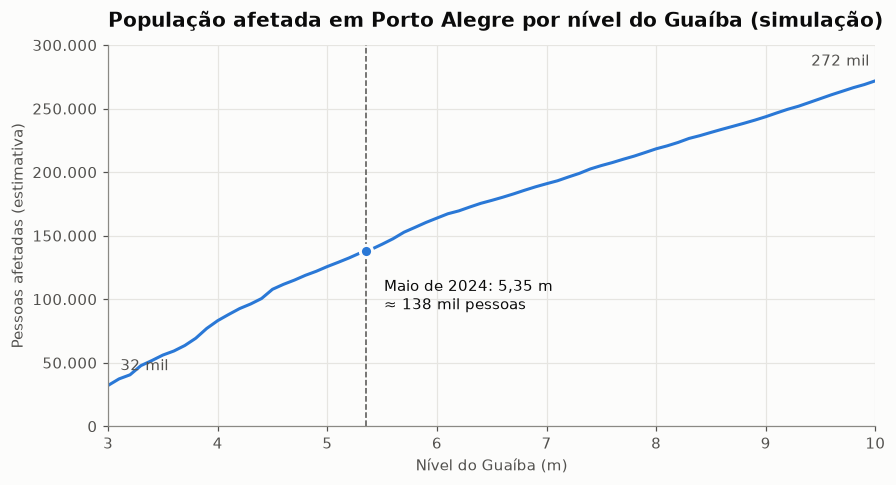

In [4]:
pessoas_535 = np.interp(PICO_2024, cidade.index, cidade["pessoas"])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(cidade.index, cidade["pessoas"], color=AZUL)
ax.axvline(PICO_2024, color=TEXTO_2, linewidth=1, linestyle="--")
ax.plot(PICO_2024, pessoas_535, "o", color=AZUL, markersize=8, markeredgecolor="#fcfcfb", markeredgewidth=2)
ax.annotate(f"Maio de 2024: 5,35 m\n≈ {pessoas_535 / 1000:.0f} mil pessoas", (PICO_2024, pessoas_535),
            xytext=(12, -38), textcoords="offset points", color=TEXTO)
for nivel, dx, alinhamento in [(3.0, 8, "left"), (10.0, -4, "right")]:
    ax.annotate(f"{cidade.loc[nivel, 'pessoas'] / 1000:.0f} mil", (nivel, cidade.loc[nivel, "pessoas"]),
                xytext=(dx, 10), textcoords="offset points", ha=alinhamento, color=TEXTO_2)
ax.set_title("População afetada em Porto Alegre por nível do Guaíba (simulação)")
ax.set_xlabel("Nível do Guaíba (m)")
ax.set_ylabel("Pessoas afetadas (estimativa)")
ax.yaxis.set_major_formatter(milhar)
ax.set_ylim(0, 300_000)
ax.set_xlim(3, 10)
plt.show()

**Comentário.** A população afetada cresce sem parar com o nível: ~32 mil pessoas a 3,0 m, ~138 mil no nível de maio de 2024 e ~272 mil a 10 m (cerca de 20% da população dos 94 bairros). A curva é mais inclinada entre 3 e 4,5 m, onde cada 10 cm acrescenta de 5 a 8 mil pessoas, e depois cresce num ritmo mais constante. 40 dos 94 bairros não são atingidos em nenhum nível.

Como a simulação só tem passos de 0,1 m, o valor em 5,35 m foi interpolado entre 5,3 m (136.389) e 5,4 m (139.190). **No dashboard**, esta é a curva obrigatória da Tela 1, e o slider pode destacar o ponto do nível escolhido.

**Limitação:** a população afetada supõe pessoas distribuídas igualmente entre todos os prédios do bairro, inclusive os não residenciais. É uma estimativa, não uma contagem.

### Gráfico 2 — Bairros com maior porcentagem de prédios afetados a 5,3 m

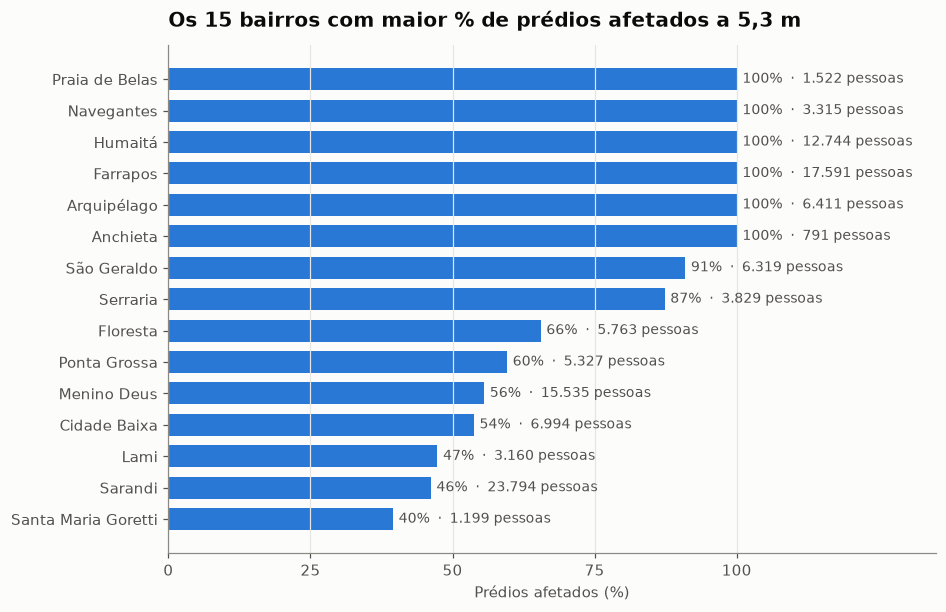

Bairros com mais pessoas afetadas a 5,3 m:


,bairro,percentage,affected_population
2239,Sarandi,46.1670,23794
2189,Farrapos,100.0000,17591
2214,Menino Deus,55.5596,15535
2195,Humaitá,100.0000,12744
2182,Cidade Baixa,53.7409,6994


In [5]:
n53 = inct[inct["nivel_m"] == 5.3]
top = n53.nlargest(15, "percentage").sort_values("percentage")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top["bairro"], top["percentage"], color=AZUL, height=0.7)
for y, (pct, pessoas) in enumerate(zip(top["percentage"], top["affected_population"])):
    ax.text(pct + 1, y, f"{pct:.0f}%  ·  {pessoas:,} pessoas".replace(",", "."), va="center", color=TEXTO_2, fontsize=9)
ax.set_title("Os 15 bairros com maior % de prédios afetados a 5,3 m")
ax.set_xlabel("Prédios afetados (%)")
ax.set_xlim(0, 135)
ax.set_xticks(range(0, 101, 25))
ax.grid(axis="y", visible=False)
plt.show()

print("Bairros com mais pessoas afetadas a 5,3 m:")
n53.nlargest(5, "affected_population")[["bairro", "percentage", "affected_population"]]

**Comentário.** Seis bairros ficam com 100% dos prédios afetados a 5,3 m: Anchieta, Arquipélago, Farrapos, Humaitá, Navegantes e Praia de Belas. São Geraldo (91%) e Serraria (87%) vêm logo depois. A maior parte está na zona norte, junto ao rio e ao Delta do Jacuí.

**Porcentagem e número de pessoas contam histórias diferentes.** Sarandi tem 46% dos prédios afetados, mas é o bairro com mais pessoas atingidas (~23,8 mil), porque é muito populoso. Menino Deus (56%, ~15,5 mil) também não aparece entre os mais críticos em porcentagem. Por isso o ranking do dashboard deveria deixar escolher entre ordenar por % de prédios e por número de pessoas.

### Gráfico 3 — Porcentagem de prédios afetados por bairro e nível

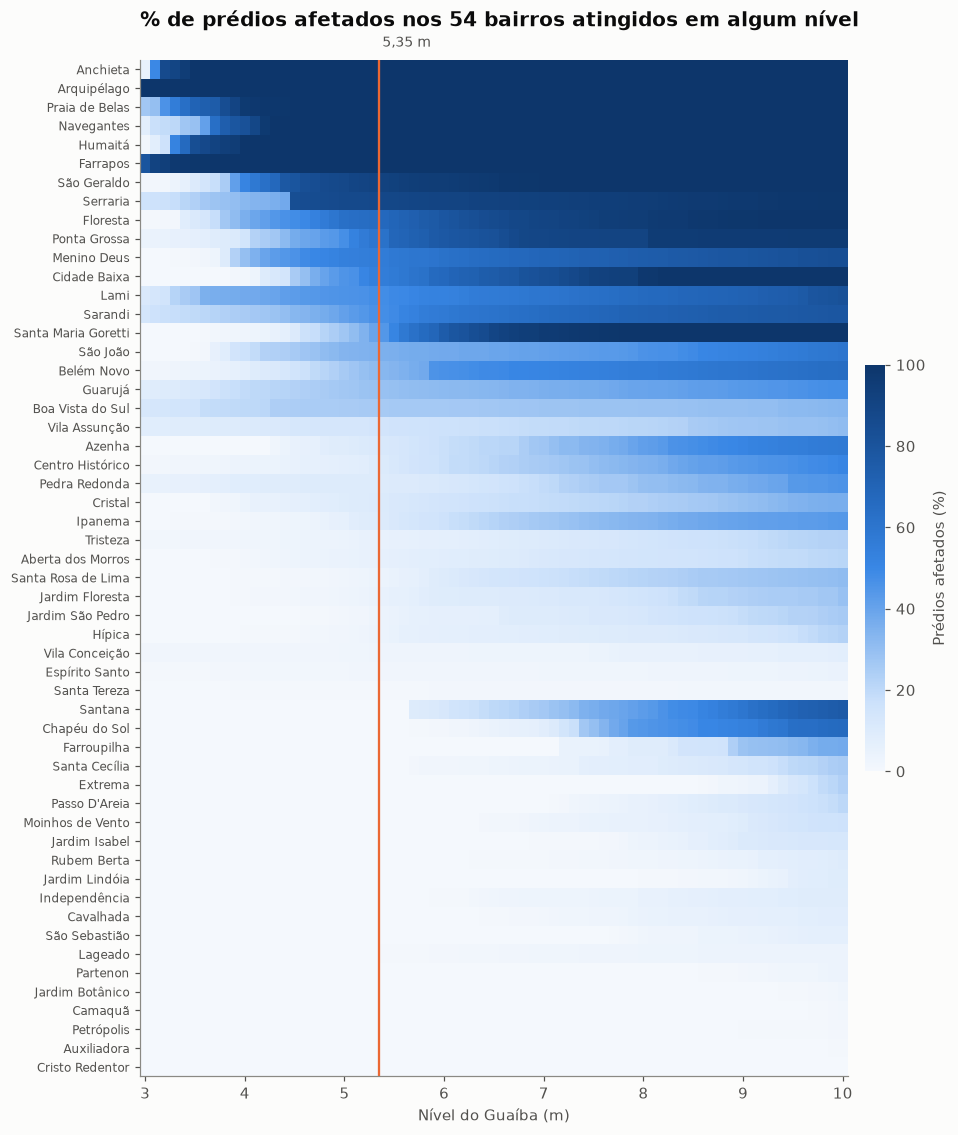

In [6]:
matriz = inct.pivot(index="bairro", columns="nivel_m", values="percentage")
matriz = matriz[matriz.max(axis=1) > 0]
# Ordem: % de prédios afetados no nível de 2024 (5,3 m), depois a 10 m
ordem = matriz[5.3].round() * 1000 + matriz[10.0]
matriz = matriz.loc[ordem.sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(10, 12))
img = ax.imshow(matriz, aspect="auto", cmap=AZUIS, vmin=0, vmax=100, interpolation="nearest")
ax.set_yticks(range(len(matriz)), matriz.index, fontsize=8)
niveis = list(matriz.columns)
ax.set_xticks([niveis.index(n) for n in [3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]], ["3", "4", "5", "6", "7", "8", "9", "10"])
ax.axvline(niveis.index(5.3) + 0.5, color=LARANJA, linewidth=1.5)
ax.text(niveis.index(5.3) + 0.8, -1.2, "5,35 m", color=TEXTO_2, fontsize=9)
ax.set_xlabel("Nível do Guaíba (m)")
ax.grid(False)
ax.set_title(f"% de prédios afetados nos {len(matriz)} bairros atingidos em algum nível", pad=22)
barra = fig.colorbar(img, ax=ax, shrink=0.4, pad=0.02)
barra.set_label("Prédios afetados (%)", color=TEXTO_2)
barra.outline.set_visible(False)
plt.show()

**Comentário.** Os bairros estão ordenados pela % de prédios afetados a 5,3 m (perto do nível de 2024) e, em empate, a 10 m. O mapa de calor mostra três grupos:

- **Bairros ribeirinhos da zona norte e do Delta** (Arquipélago, Farrapos, Anchieta, Humaitá, Navegantes...). Já estão atingidos a 3,0 m e chegam a quase 100% antes de 5 m.
- **Bairros que entram entre 4 e 6 m** (Menino Deus, Cidade Baixa, Santa Maria Goretti, São João...). Passam rápido de 40–50%, e é aí que a curva da cidade cresce bastante.
- **Bairros que só entram em níveis altos** (acima de 7 m). A porcentagem fica baixa mesmo a 10 m, porque só a parte mais baixa do bairro alaga.

Depois de entrar, nenhum bairro "sai" da lista: depois da limpeza, a porcentagem só sobe com o nível. Esta visão é a base do mapa opcional da Tela 1, que colore os bairros pela porcentagem no nível escolhido.

### Gráfico 4 — Efeito da limpeza na população afetada

,registros,bairros
tipo,,
maior_que_nivel_superior,5,1
ordem_dos_bairros,1,0
oscilacao_pequena,65,1
percentual_arredondado_para_cima,1292,52
percentual_fora_da_regra,2,1
pico_isolado,1,1
queda_para_zero,4,3


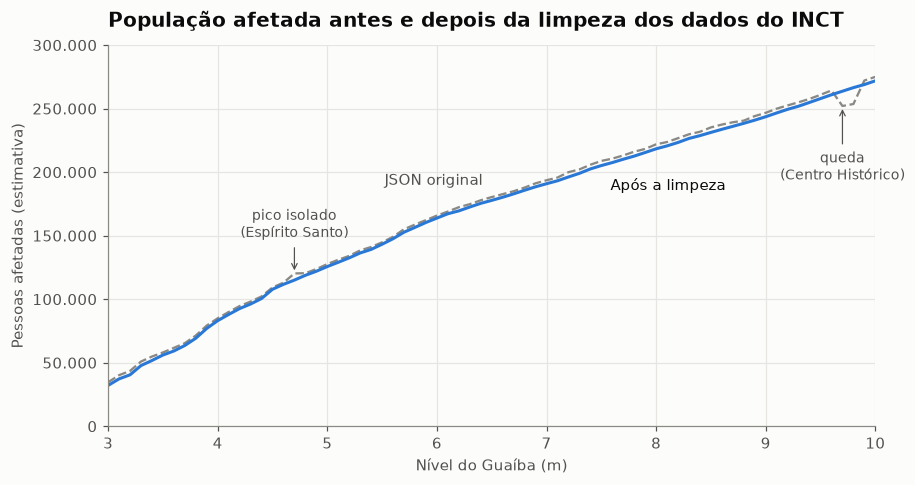

Níveis em que o total da cidade cai com o rio subindo:
  original: [9.7]
  limpo:    []


In [7]:
log_inct = pd.read_csv(PROC / "inct_inconsistencias.csv")
display(log_inct.groupby("tipo").agg(registros=("tipo", "size"), bairros=("bairro", "nunique")))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(cidade.index, cidade["pessoas_original"], color=CINZA_REF, linewidth=1.5, linestyle="--")
ax.plot(cidade.index, cidade["pessoas"], color=AZUL)
ax.annotate("JSON original", (6.5, cidade.loc[6.5, "pessoas_original"]), xytext=(-6, 8),
            textcoords="offset points", ha="right", color=TEXTO_2)
ax.annotate("Após a limpeza", (7.5, cidade.loc[7.5, "pessoas"]), xytext=(6, -16),
            textcoords="offset points", color=TEXTO)
for nivel, rotulo, dy in [(4.7, "pico isolado\n(Espírito Santo)", 32), (9.7, "queda\n(Centro Histórico)", -40)]:
    ax.annotate(rotulo, (nivel, cidade.loc[nivel, "pessoas_original"]), xytext=(0, dy),
                textcoords="offset points", ha="center", va="center", color=TEXTO_2, fontsize=9,
                arrowprops=dict(arrowstyle="->", color=TEXTO_2, linewidth=0.8))
ax.set_title("População afetada antes e depois da limpeza dos dados do INCT")
ax.set_xlabel("Nível do Guaíba (m)")
ax.set_ylabel("Pessoas afetadas (estimativa)")
ax.yaxis.set_major_formatter(milhar)
ax.set_xlim(3, 10)
ax.set_ylim(0, 300_000)
plt.show()

print("Níveis em que o total da cidade cai com o rio subindo:")
print("  original:", list(cidade.index[cidade["pessoas_original"].diff() < 0]))
print("  limpo:   ", list(cidade.index[cidade["pessoas"].diff() < 0]))

**Comentário.** As duas curvas são quase iguais na forma, mas a original fica sempre ~2 a 3 mil pessoas acima. Isso vem do `percentage`, que no JSON é arredondado **para cima** e para inteiro: um bairro com 0,09% dos prédios afetados aparece com 1%, e a população afetada dele sai cerca de 10 vezes maior. A diferença é pequena na cidade, mas grande em bairros com poucos prédios atingidos.

A curva original também tem dois saltos sem sentido físico. A 4,7 m aparece um **pico isolado** no Espírito Santo (46 → 2.101 → 47 prédios). A 9,7 m o total da cidade **cai** com o rio subindo, porque o Centro Histórico vai de 2.050 prédios afetados para zero. A limpeza corrige os dois casos. O relatório `relatorios/limpeza_dados.pdf` detalha cada inconsistência e o tratamento escolhido.

## Parte 2 — Tela 2: nível do Guaíba (ANA)

Dados coletados por código na API HidroWebService da ANA (`scripts/coleta_ana_hidroweb.py`). O serviço antigo da ANA (`scripts/coleta_ana_guaiba.py`) traz os mesmos valores e fica no repositório só para conferência. **Cada régua tem o seu próprio zero**, então valores de estações diferentes não são somados nem ajustados entre si: cada uma é analisada separadamente.

| Código | Estação | Tipo | Período nos dados | Uso |
|---|---|---|---|---|
| 87450004 | Cais Mauá C6 | telemétrica (15 min) | 2014–2026 | régua oficial das cotas de alerta (2,55 m) e inundação (3,00 m) |
| 87444000 | Usina do Gasômetro (cheia 2024) | telemétrica | mai/2024–ago/2025 | registrou o pico de 5,35 m |
| 87450020 | Usina do Gasômetro | telemétrica | mai/2024–2026 | — |
| 87450000 | Porto Alegre | convencional (diária) | 1929–1980 | inclui a cheia de 1941 |
| 87450003 | Praça da Harmonia | convencional (diária) | 1941–2008 | — |

**Fonte:** ANA, HidroWebService, https://www.ana.gov.br/hidrowebservice. A data de cada requisição fica registrada em `dados/originais/ana_hidroweb/coleta_log.csv`.

In [8]:
estacoes = pd.read_csv(PROC / "ana_estacoes.csv")
diario = pd.read_csv(PROC / "ana_nivel_diario.csv", parse_dates=["data"])
historico = pd.read_csv(PROC / "ana_historico_diario.csv", parse_dates=["data"])
data_coleta = pd.read_csv(RAIZ / "dados" / "originais" / "ana_hidroweb" / "coleta_log.csv")["data_coleta"].max()
print("Última coleta:", data_coleta)
diario.groupby("codigo").agg(inicio=("data", "min"), fim=("data", "max"), dias=("data", "size"),
                             maximo_m=("nivel_max_m", "max"))

Última coleta: 2026-11-05T17:26:35


,inicio,fim,dias,maximo_m
codigo,,,,
87444000,2024-05-03,2025-08-07,462,5.35
87450004,2014-07-29,2026-11-05,3606,3.69
87450020,2024-05-03,2026-11-05,887,4.17


### Gráfico 5 — Nível diário do Guaíba no Cais Mauá, 2014–2026

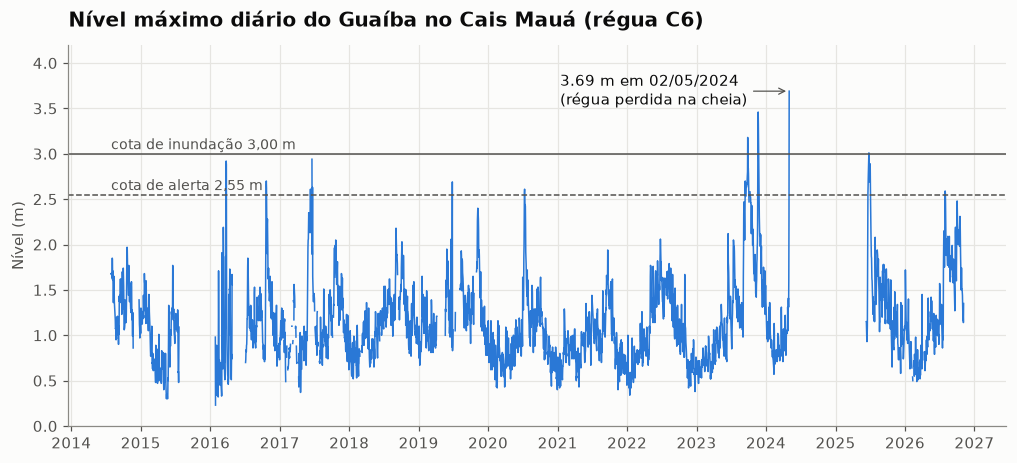

Dias sem leitura válida: 877 de 4483


In [9]:
mauá = diario[diario["codigo"] == 87450004].set_index("data")["nivel_max_m"]
mauá = mauá.asfreq("D")  # dias sem leitura viram lacunas no gráfico

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(mauá.index, mauá, color=AZUL, linewidth=1)
for cota, rotulo, estilo in [(COTA_INUNDACAO, "cota de inundação 3,00 m", "-"), (COTA_ALERTA, "cota de alerta 2,55 m", "--")]:
    ax.axhline(cota, color=TEXTO_2, linewidth=1, linestyle=estilo)
    ax.text(mauá.index.min(), cota + 0.05, rotulo, color=TEXTO_2, fontsize=9)
maximo = mauá.idxmax()
ax.annotate(f"{mauá.max():.2f} m em {maximo:%d/%m/%Y}\n(régua perdida na cheia)", (maximo, mauá.max()),
            xytext=(-150, 0), textcoords="offset points", va="center", color=TEXTO,
            arrowprops=dict(arrowstyle="->", color=TEXTO_2, linewidth=0.8))
ax.set_title("Nível máximo diário do Guaíba no Cais Mauá (régua C6)")
ax.set_ylabel("Nível (m)")
ax.set_ylim(0, 4.2)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()

print(f"Dias sem leitura válida: {mauá.isna().sum()} de {len(mauá)}")

**Comentário.** Na maior parte do tempo o Guaíba fica entre 0,5 e 1,5 m no Cais Mauá. A série mostra a **sazonalidade**: o nível costuma subir no inverno e na primavera (jun–out) e baixar no verão. Até 2022 ele nunca passou da cota de inundação; os anos de 2015 a 2017 chegaram perto, com picos de 2,7 a 2,9 m.

A partir de setembro de 2023 começa a sequência de cheias. A de maio de 2024 aparece **cortada** em 3,69 m, porque a régua do Cais Mauá foi perdida em 02/05/2024; o pico real só foi registrado no Gasômetro (Gráfico 7). Depois disso a estação ficou sem dados até junho de 2025. As lacunas são dias sem leitura válida: falhas do sensor e trechos descartados na limpeza, como o sensor travado em 2015–2016.

### Gráfico 6 — Dias por ano acima das cotas de alerta e de inundação

,dias_com_dados,acima_alerta,acima_inundacao
ano,,,
2014,126,0,0
2015,204,2,0
2016,269,5,0
2017,310,5,0
2018,347,0,0
2019,275,1,0
2020,366,2,0
2021,365,0,0
2022,365,0,0


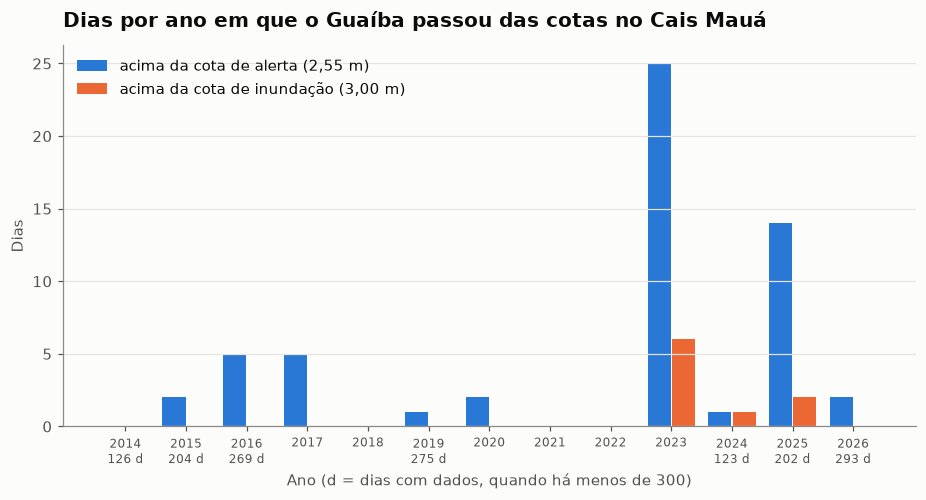

In [10]:
mauá_dia = diario[diario["codigo"] == 87450004].assign(ano=lambda d: d["data"].dt.year)
por_ano = mauá_dia.groupby("ano").agg(
    dias_com_dados=("data", "size"),
    acima_alerta=("nivel_max_m", lambda s: (s >= COTA_ALERTA).sum()),
    acima_inundacao=("nivel_max_m", lambda s: (s >= COTA_INUNDACAO).sum()),
)
display(por_ano)

x = np.arange(len(por_ano))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - 0.2, por_ano["acima_alerta"], width=0.38, color=AZUL, label="acima da cota de alerta (2,55 m)")
ax.bar(x + 0.2, por_ano["acima_inundacao"], width=0.38, color=LARANJA, label="acima da cota de inundação (3,00 m)")
rotulos = [f"{ano}\n{linha['dias_com_dados']} d" if linha["dias_com_dados"] < 300 else str(ano)
           for ano, linha in por_ano.iterrows()]
ax.set_xticks(x, rotulos, fontsize=8)
ax.set_xlabel("Ano (d = dias com dados, quando há menos de 300)")
ax.set_title("Dias por ano em que o Guaíba passou das cotas no Cais Mauá")
ax.set_ylabel("Dias")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
plt.show()

**Comentário.** É a pergunta central da Tela 2: **com que frequência o Guaíba passou da cota de inundação?** De 2014 a 2022, **nenhuma vez** no Cais Mauá. Depois disso: 6 dias em 2023, 1 em 2024 e 2 em 2025. A cota de alerta também mudou de patamar: no máximo 5 dias por ano até 2022, contra 25 em 2023 e 14 em 2025.

**Cuidados na leitura:**
- **2024 está subestimado.** A régua foi perdida no início de maio, e a série só tem 123 dias nesse ano. O rio ficou acima de 3 m por semanas, mas isso só aparece no Gasômetro.
- **Anos com menos de 300 dias com dados** (indicados no eixo) podem ter cheias não registradas.
- **Picos isolados foram removidos.** Na exploração dos dados brutos, 2017 e 2019 pareciam ter dias acima de 3 m, mas eram leituras isoladas com erro (ver `ana_inconsistencias.csv`).

No dashboard, o **filtro de período** da Tela 2 entra neste gráfico e no anterior.

### Gráfico 7 — Cheia de maio de 2024 nas três réguas e ligação com a Tela 1

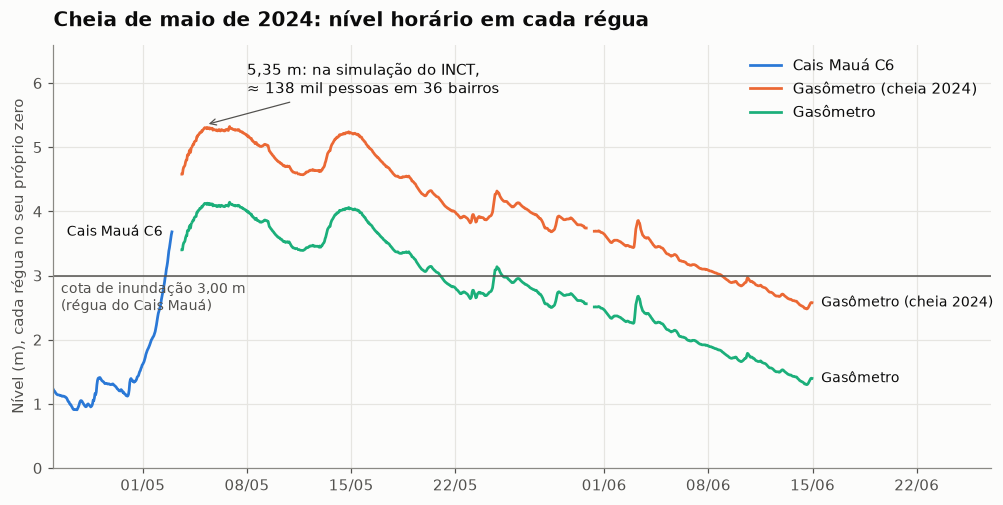

Cais Mauá C6: máximo 3.69 m em 02/05 23:15; acima de 3 m de 02/05 a 02/05
Gasômetro (cheia 2024): máximo 5.35 m em 05/05 05:30; acima de 3 m de 03/05 a 08/06
Gasômetro: máximo 4.17 m em 05/05 05:30; acima de 3 m de 03/05 a 25/05


In [11]:
tele = pd.read_csv(PROC / "ana_telemetria_15min.csv.gz", parse_dates=["data_hora"])
janela = tele[(tele["data_hora"] >= "2024-04-25") & (tele["data_hora"] < "2024-06-15")]
reguas = [(87450004, "Cais Mauá C6", AZUL), (87444000, "Gasômetro (cheia 2024)", LARANJA),
          (87450020, "Gasômetro", VERDE_AGUA)]

fig, ax = plt.subplots(figsize=(11, 5))
for codigo, nome, cor in reguas:
    serie = janela[janela["codigo"] == codigo].set_index("data_hora")["nivel_m"].resample("1h").mean()
    ax.plot(serie.index, serie, color=cor, linewidth=1.8, label=nome)
    fim = serie.dropna()
    ax.annotate(nome, (fim.index[-1], fim.iloc[-1]), xytext=(6 if codigo != 87450004 else -6, 0), textcoords="offset points",
                va="center", ha="left" if codigo != 87450004 else "right", color=TEXTO, fontsize=9)
ax.axhline(COTA_INUNDACAO, color=TEXTO_2, linewidth=1)
ax.text(pd.Timestamp("2024-04-25 12:00"), COTA_INUNDACAO - 0.08, "cota de inundação 3,00 m\n(régua do Cais Mauá)", color=TEXTO_2, fontsize=9, va="top")
ax.annotate(f"5,35 m: na simulação do INCT,\n≈ {pessoas_535 / 1000:.0f} mil pessoas em {cidade.loc[5.3, 'bairros']} bairros",
            (pd.Timestamp("2024-05-05 05:30"), PICO_2024), xytext=(pd.Timestamp("2024-05-08"), 6.05),
            va="center", color=TEXTO,
            arrowprops=dict(arrowstyle="->", color=TEXTO_2, linewidth=0.8))
ax.set_title("Cheia de maio de 2024: nível horário em cada régua")
ax.set_ylabel("Nível (m), cada régua no seu próprio zero")
ax.set_ylim(0, 6.6)
ax.set_xlim(pd.Timestamp("2024-04-25"), pd.Timestamp("2024-06-27"))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.legend(loc="upper right")
plt.show()

for codigo, nome, _ in reguas:
    s = janela[janela["codigo"] == codigo]
    acima = s[s["nivel_m"] >= COTA_INUNDACAO]["data_hora"]
    print(f"{nome}: máximo {s['nivel_m'].max():.2f} m em {s.loc[s['nivel_m'].idxmax(), 'data_hora']:%d/%m %H:%M}"
          + (f"; acima de 3 m de {acima.min():%d/%m} a {acima.max():%d/%m}" if len(acima) else ""))

**Comentário.** É a visualização que **liga a Tela 2 à Tela 1**, pelo nível do Guaíba e pela enchente de 2024:

- A régua do Cais Mauá sobe até 3,69 m e para de medir em 02/05.
- As duas réguas do Gasômetro começam a medir em 03/05. A de emergência registra o recorde de **5,35 m em 05/05**, o mesmo nível marcado na curva da Tela 1, e fica acima de 3 m até 08/06. Na simulação do INCT, esse nível corresponde a ~138 mil pessoas afetadas.
- As duas réguas do Gasômetro têm formas idênticas e uma diferença quase constante (~1,2 m), o que confirma que **cada régua tem um zero diferente**. Por isso os valores não são comparados entre estações, e a cota de 3,00 m vale só para o Cais Mauá.

**Ideia para o dashboard:** ao escolher um nível no slider da Tela 1, a Tela 2 mostra se e quando o Guaíba já chegou a esse nível.

### Gráfico 8 — Nível máximo por ano nas réguas antigas e atuais

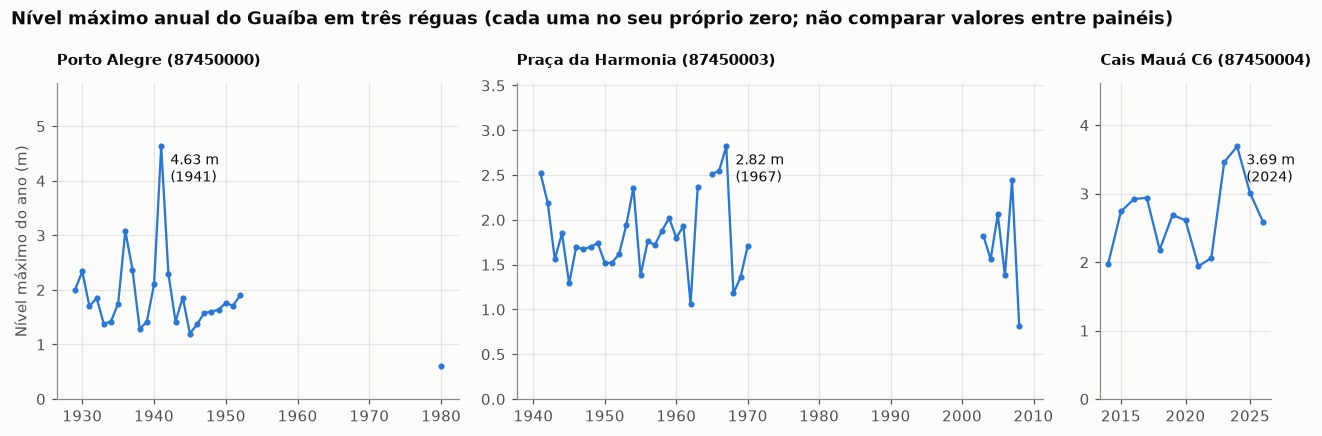

In [12]:
anuais = [
    ("Porto Alegre (87450000)", historico[historico["codigo"] == 87450000].set_index("data")["nivel_m"]),
    ("Praça da Harmonia (87450003)", historico[historico["codigo"] == 87450003].set_index("data")["nivel_m"]),
    ("Cais Mauá C6 (87450004)", diario[diario["codigo"] == 87450004].set_index("data")["nivel_max_m"]),
]

fig, eixos = plt.subplots(1, 3, figsize=(12, 4), gridspec_kw={"width_ratios": [52, 68, 22]})
for ax, (nome, serie) in zip(eixos, anuais):
    maximo = serie.groupby(serie.index.year).max()
    maximo = maximo.reindex(range(maximo.index.min(), maximo.index.max() + 1))  # anos sem dados viram lacuna
    ax.plot(maximo.index, maximo, color=AZUL, linewidth=1.5, marker="o", markersize=3)
    ano = maximo.idxmax()
    ax.annotate(f"{maximo.max():.2f} m\n({ano})", (ano, maximo.max()), xytext=(6, -4), textcoords="offset points",
                va="top", color=TEXTO, fontsize=9)
    ax.set_title(nome, fontsize=10)
    ax.set_ylim(0, maximo.max() * 1.25)
eixos[2].set_xticks([2015, 2020, 2025])
eixos[0].set_ylabel("Nível máximo do ano (m)")
fig.suptitle("Nível máximo anual do Guaíba em três réguas (cada uma no seu próprio zero; não comparar valores entre painéis)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

**Comentário.** As estações convencionais (leitura manual diária) estendem a série histórica para trás. Cada painel tem a sua própria escala, porque **as réguas não têm o mesmo zero**:

- **Porto Alegre (1929–1980):** o máximo é a cheia de **maio de 1941**, com 4,63 m nesta régua. A marca histórica de 4,76 m costuma ser citada em outra referência, o que é mais um exemplo de diferença de zero.
- **Praça da Harmonia (1941–2008):** a régua começou depois da cheia de 1941. O maior valor é o de 1967.
- **Cais Mauá (2014–2026):** os máximos de 2023 a 2025 são os maiores da série. O de 2024 aparece subestimado porque a régua foi perdida.

O inventário da ANA indica o fim da estação Porto Alegre em 1952, mas os dados vão até 1980. A divergência fica registrada em `ana_inconsistencias.csv`.

## Resumo e próximos passos

| # | Gráfico | Tela | Elemento do dashboard |
|---|---|---|---|
| 1 | População afetada × nível | 1 | curva obrigatória com 5,35 m marcado |
| 2 | Top 15 bairros a 5,3 m | 1 | ranking do nível escolhido |
| 3 | Mapa de calor bairro × nível | 1 | gráfico de % por bairro / mapa opcional |
| 4 | Antes e depois da limpeza | 1 | aviso de limitações e relatório de limpeza |
| 5 | Série diária do Cais Mauá | 2 | série histórica com filtro de período |
| 6 | Dias acima das cotas por ano | 2 | resposta à pergunta da Tela 2 |
| 7 | Cheia de maio de 2024 | 2 | ligação com a Tela 1 (nível e enchente de 2024) |
| 8 | Máximo anual nas réguas | 2 | contexto histórico |

**Principais achados**
- Na simulação, o nível de maio de 2024 atinge ~138 mil pessoas em 36 bairros. Seis bairros ficam com 100% dos prédios afetados.
- Porcentagem e número de pessoas apontam bairros diferentes (Sarandi × Arquipélago): vale mostrar as duas coisas.
- O JSON superestima a população afetada em ~2 a 3 mil pessoas por nível, por causa do arredondamento para cima.
- O Guaíba não passou da cota de inundação no Cais Mauá de 2014 a 2022, e passou em 2023, 2024 e 2025.

**Falta:** os gráficos dos gastos estaduais com prevenção (Portal da Transparência RS), que completam a pergunta da Tela 2.